# Which WHACS node to use? Ranking the nodes of an area against SWOT

Give an **area of interest** (and, optionally, the point where you need the waves): the
notebook finds every node of the WHACS hindcast in the area, compares its significant wave
height with **SWOT KaRIn** (2 km pixels up to a few km from the coast) and with the
**altimeters** (IMOS, along-track), and ranks the nodes by their error against the
satellites. Use it to choose the node that forces a coastal model or feeds a downscaling.

Everything is read over HTTP from the public GeoOcean Zarr stores (only the chunks needed are
downloaded), so it runs anywhere. WHACS here is the bulk store (Hs, periods, directions,
hourly 1979 to 2026-01 on its global SMC grid, ~7 km near the coast).

Related notebooks in this folder:
- `Altimetry_IMOS_Zarr`: the altimeter record (1985-present) around a point
- `SWOT_KaRIn_Zarr`: SWOT's 2D wave heights up to a few km from the coast
- `WHACS_Validation_Zarr`: one WHACS node against both satellites

Requirements: `bluemath-tk` (`bluemath_tk.waves.altimetry`), `xarray`, `zarr>=3`, `fsspec`, `aiohttp`, `matplotlib`, `cartopy`.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from bluemath_tk.core.metrics import compute_metrics
from bluemath_tk.waves.altimetry import (
    altimeter_near, altimeter_near_points, altimeter_passes, collocate, haversine_km, open_altimeter,
)

# Public GeoOcean Zarr stores (read over HTTP, only the chunks needed are downloaded).
# On the GeoOcean cluster, "http://geocean01.sci.unican.es/zarr" is faster.
BASE = "https://geoocean.unican.es/zarr"
IMOS_URL = f"{BASE}/IMOS/imos_altimeter_dm00.zarr"
SWOT_URL = f"{BASE}/SWOT/swot_karin_windwave.zarr"
WHACS_URL = f"{BASE}/CSIRO/whacs_global_smc_1h_bulk_1979_2026.zarr"

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

## Settings

- `AOI`: the area, `(lon_min, lon_max, lat_min, lat_max)` in degrees.
- `TARGET`, `MAX_DISTANCE_KM`: the point where you need the waves and how far from it a node
  may be (`TARGET = None` ranks the whole area). Nodes far offshore usually score best, so
  without a target the "best" node may simply be the most offshore one.
- `PERIOD`: SWOT's science orbit starts in 2023-07 and WHACS ends in 2026-01.
- The SWOT reading (pixels within `SWOT_RADIUS_KM` of the node, at least `MIN_DIST2COAST_KM`
  from the coast, quality 0, one median per pass) is the one that matched coastal buoys best.
  The altimeters use a wider circle (`IMOS_RADIUS_KM`, water deeper than `IMOS_MIN_DEPTH`).
- `NADIR_SCREEN`: drop the KaRIn passes much higher than the SWOT nadir altimeter of the same pass
  (artefacts; explained below).
- `MIN_PASSES`: nodes with fewer SWOT passes are not ranked; `RANK_BY`: the metric that ranks.

In [2]:
AOI = (-4.2, -3.3, 43.4, 43.9)  # Cantabrian coast around Santander
TARGET = (-3.80, 43.50)  # lon, lat; None to rank the whole area
MAX_DISTANCE_KM = 20.0
PERIOD = slice("2023-07-01", "2026-01-31")

SWOT_RADIUS_KM, MIN_DIST2COAST_KM = 5.0, 2.0
IMOS_RADIUS_KM, IMOS_MIN_DEPTH = 25.0, 10.0
NADIR_SCREEN = True
MIN_PASSES = 30
RANK_BY = "rmse"  # any metric below where lower is better: "rmse", "si", "abs_bias"

## WHACS nodes in the area

In [3]:
whacs = xr.open_zarr(WHACS_URL)
lon_all = (whacs.longitude.values + 180) % 360 - 180
lat_all = whacs.latitude.values
inside = np.flatnonzero((lon_all >= AOI[0]) & (lon_all <= AOI[1]) & (lat_all >= AOI[2]) & (lat_all <= AOI[3]))
nodes = pd.DataFrame({"seapoint": inside, "lon": lon_all[inside], "lat": lat_all[inside]})
if TARGET is not None:
    nodes["distance_km"] = haversine_km(nodes.lon.to_numpy(), nodes.lat.to_numpy(), *TARGET)
print(f"{len(nodes)} WHACS nodes in the area")
nodes.head()

53 WHACS nodes in the area


,seapoint,lon,lat,distance_km
0,2297047,-4.1875,43.4375,32.034004
1,2297048,-4.1250,43.4375,27.132511
2,2297049,-3.3750,43.4375,34.994354
3,2297050,-3.3125,43.4375,39.950153
4,2297102,-4.1875,43.5000,31.254902


## Hindcast Hs at every node

One read for all the nodes: the store is chunked 372 hours x 11,551 nodes, so nearby nodes
share their chunks.

In [4]:
hs = whacs.hs.isel(seapoint=nodes.seapoint.to_numpy()).sel(time=PERIOD).load()
print(f"{hs.sizes['time']:,} hours x {hs.sizes['seapoint']} nodes")

22,704 hours x 53 nodes


## Satellite passes near every node

`altimeter_near_points` reads the 1-degree cells around all the nodes once and gives each
node the observations within its radius; `altimeter_passes` then keeps one median per pass (SWOT zeros are kept inside the
median, as recommended; a pass whose median is 0 failed and is dropped).

A few KaRIn passes with quality flag 0 read far too high (4-8 m in a 2 m sea; rain cells or
backscatter blooms), and neither the flag nor the spread of the pixels shows it. SWOT also carries a
classic **nadir altimeter** (in the IMOS store, satellite `SWOT`) that measures the same pass at the
same instant, between the two swaths (~10-60 km from the KaRIn pixels). A KaRIn pass is dropped when
it is **higher** than the nadir by more than `max(0.75 m, 25 %)`. Only higher: near the coast KaRIn
is rightly lower than the nadir offshore. Passes without a nadir value are kept. Real storms pass
the screen, because the nadir sees them too.

In [5]:
swot = open_altimeter(SWOT_URL)
imos = open_altimeter(IMOS_URL)
swot_obs = altimeter_near_points(swot, nodes.lon, nodes.lat, radius_km=SWOT_RADIUS_KM,
                                 time=PERIOD, min_dist2coast=MIN_DIST2COAST_KM)
imos_obs = altimeter_near_points(imos, nodes.lon, nodes.lat, radius_km=IMOS_RADIUS_KM,
                                 time=PERIOD, min_depth=IMOS_MIN_DEPTH)
print(f"SWOT: {len(swot_obs):,} pixels; altimeters: {len(imos_obs):,} observations")

# SWOT nadir passes over the area (one per SWOT pass)
names = np.array(imos.satellite.attrs["flag_meanings"].split())
centre = ((AOI[0] + AOI[1]) / 2, (AOI[2] + AOI[3]) / 2)
nadir = altimeter_passes(altimeter_near(imos, *centre, radius_km=100, time=PERIOD, min_depth=IMOS_MIN_DEPTH))
nadir = nadir[names[nadir.satellite.astype(int)] == "SWOT"]
print(f"SWOT nadir: {len(nadir)} passes within 100 km of the area centre")


def screen_with_nadir(passes, nadir, tol_m=0.75, tol_rel=0.25, window="15min"):
    """KaRIn passes with the nadir Hs of the same pass (``nadir_hs``) and ``ok``: False when
    KaRIn is higher than the nadir by more than max(tol_m, tol_rel x nadir)."""
    same_pass = nadir[["hs"]].rename(columns={"hs": "nadir_hs"})
    same_pass = same_pass[~same_pass.index.duplicated()].sort_index()
    out = pd.merge_asof(passes.sort_index(), same_pass, left_index=True, right_index=True,
                        tolerance=pd.Timedelta(window), direction="nearest")
    excess = out.hs - out.nadir_hs
    out["ok"] = out.nadir_hs.isna() | (excess <= np.maximum(tol_m, tol_rel * out.nadir_hs))
    return out

SWOT: 88,716 pixels; altimeters: 101,562 observations


SWOT nadir: 174 passes within 100 km of the area centre


## Error of every node

For each node and satellite, the hindcast at the pass times (nearest hour) against the pass
Hs. The **satellite is the reference** (Hs pairs $o_i$ observed, $m_i$ hindcast, $n$ passes):

| metric | formula | reads |
| --- | --- | --- |
| `n` | number of passes | what the numbers rest on |
| `bias` | $\frac{1}{n}\sum (m_i - o_i)$ | > 0: the hindcast is too high |
| `rmse` | $\sqrt{\frac{1}{n}\sum (m_i - o_i)^2}$ | typical error (m) |
| `si` | $\mathrm{rmse}\,/\,\bar{o}$ | error relative to the mean sea state |
| `r` | Pearson correlation of $m$ and $o$ | timing of the sea states |
| `slope` | slope of the least-squares line $m = a\,o + b$ | < 1: storms too low |

(`bluemath_tk.core.metrics.compute_metrics(reference, estimate)`.)

In [6]:
METRICS = ["bias", "rmse", "si", "r", "slope"]


def node_metrics(obs, hs, k, screen=False):
    """Metrics of node k against the passes in obs (only n when fewer than 3 pairs)."""
    passes = altimeter_passes(obs[obs.point == k])
    passes = passes[passes.hs > 0]  # a patch median of 0 is a failed SWOT retrieval
    screened = 0
    if screen:
        passes = screen_with_nadir(passes, nadir)
        screened = int((~passes.ok).sum())
        passes = passes[passes.ok].drop(columns=["nadir_hs", "ok"])
    pairs = collocate(hs.isel(seapoint=k).to_dataframe()[["hs"]], passes)
    if len(pairs) < 3:
        return {"n": len(pairs), "screened": screened}, pairs
    return compute_metrics(pairs.sat_hs, pairs.hs, METRICS) | {"screened": screened}, pairs


rows, pairs = [], {}
for k in range(len(nodes)):
    row = {}
    for name, obs in (("swot", swot_obs), ("imos", imos_obs)):
        m, pairs[name, k] = node_metrics(obs, hs, k, screen=NADIR_SCREEN and name == "swot")
        row |= {f"{name}_{key}": value for key, value in m.items()}
    rows.append(row)
scores = pd.concat([nodes, pd.DataFrame(rows)], axis=1)
scores["swot_abs_bias"] = scores.swot_bias.abs()

## Ranking

Nodes with at least `MIN_PASSES` SWOT passes (and within `MAX_DISTANCE_KM` of the target),
ranked by `RANK_BY` against SWOT; the altimeter columns are a second, independent opinion
(more passes, but along-track and farther from the coast).

In [7]:
eligible = scores.swot_n >= MIN_PASSES
if TARGET is not None:
    eligible &= scores.distance_km <= MAX_DISTANCE_KM
ranking = scores[eligible].sort_values(f"swot_{RANK_BY}").reset_index(drop=True)
best = ranking.iloc[0]
print(f"best node: seapoint {int(best.seapoint)} at ({best.lon:.3f}, {best.lat:.3f}), "
      f"SWOT {RANK_BY} {best[f'swot_{RANK_BY}']:.3f} on {int(best.swot_n)} passes")
columns = ["seapoint", "lon", "lat", *(["distance_km"] if TARGET is not None else []),
           "swot_n", "swot_screened", "swot_bias", "swot_rmse", "swot_si", "swot_r", "imos_n", "imos_bias", "imos_rmse"]
ranking[columns].head(10).round(3)

best node: seapoint 2297280 at (-3.750, 43.625), SWOT rmse 0.354 on 108 passes


,seapoint,lon,lat,distance_km,swot_n,swot_screened,swot_bias,swot_rmse,swot_si,swot_r,imos_n,imos_bias,imos_rmse
0,2297280,-3.750,43.625,14.471,108,6,-0.223,0.354,0.120,0.969,303,-0.196,0.382
1,2297281,-3.688,43.625,16.594,106,6,-0.232,0.371,0.126,0.965,399,-0.182,0.367
2,2297279,-3.812,43.625,13.936,144,9,-0.211,0.380,0.137,0.960,271,-0.197,0.368
3,2297110,-3.688,43.500,9.074,107,5,-0.194,0.395,0.176,0.940,237,-0.474,0.619
4,2297282,-3.625,43.625,19.799,108,6,-0.246,0.397,0.136,0.960,444,-0.186,0.358
5,2297278,-3.875,43.625,15.156,144,9,-0.195,0.402,0.149,0.959,265,-0.178,0.350
6,2297188,-3.750,43.562,8.034,108,6,-0.250,0.415,0.150,0.951,271,-0.291,0.448
7,2297105,-4.000,43.500,16.132,107,4,-0.275,0.418,0.146,0.953,153,-0.313,0.447
8,2297189,-3.688,43.562,11.426,109,6,-0.285,0.445,0.156,0.945,314,-0.317,0.472
9,2297109,-3.750,43.500,4.033,105,6,-0.189,0.445,0.198,0.925,214,-0.440,0.618


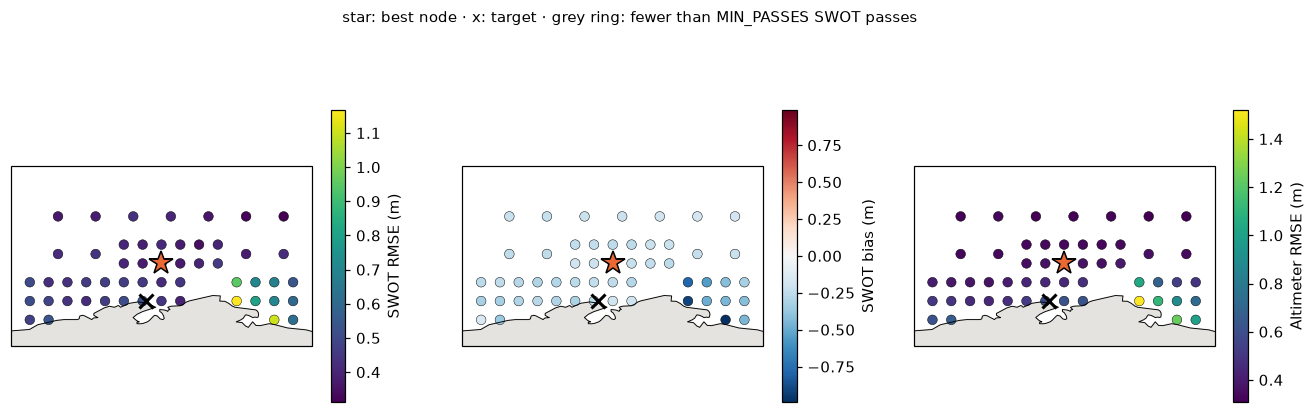

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), subplot_kw={"projection": ccrs.PlateCarree()})
panels = [("swot_rmse", "SWOT RMSE (m)", "viridis", None), ("swot_bias", "SWOT bias (m)", "RdBu_r", "sym"),
          ("imos_rmse", "Altimeter RMSE (m)", "viridis", None)]
for ax, (col, label, cmap, sym) in zip(axes, panels):
    ax.set_extent([AOI[0] - 0.05, AOI[1] + 0.05, AOI[2] - 0.05, AOI[3] + 0.05])
    ax.add_feature(cfeature.LAND.with_scale("10m"), color="#e4e3df", zorder=0)
    ax.coastlines("10m", lw=0.6)
    lim = np.nanmax(np.abs(scores[col])) if sym else None
    sc = ax.scatter(scores.lon, scores.lat, c=scores[col], s=40, cmap=cmap, edgecolor="k", lw=0.3,
                    vmin=-lim if sym else None, vmax=lim, transform=ccrs.PlateCarree())
    few = scores.swot_n < MIN_PASSES
    ax.scatter(scores.lon[few], scores.lat[few], s=40, facecolor="none", edgecolor=GREY, lw=1.2,
               transform=ccrs.PlateCarree())
    ax.plot(best.lon, best.lat, "*", color=ORANGE, ms=16, mec="k", transform=ccrs.PlateCarree())
    if TARGET is not None:
        ax.plot(*TARGET, "x", color="k", ms=9, mew=2, transform=ccrs.PlateCarree())
    plt.colorbar(sc, ax=ax, label=label, shrink=0.75)
fig.suptitle("star: best node · x: target · grey ring: fewer than MIN_PASSES SWOT passes", fontsize=10)
plt.show()

## The best node against the satellites

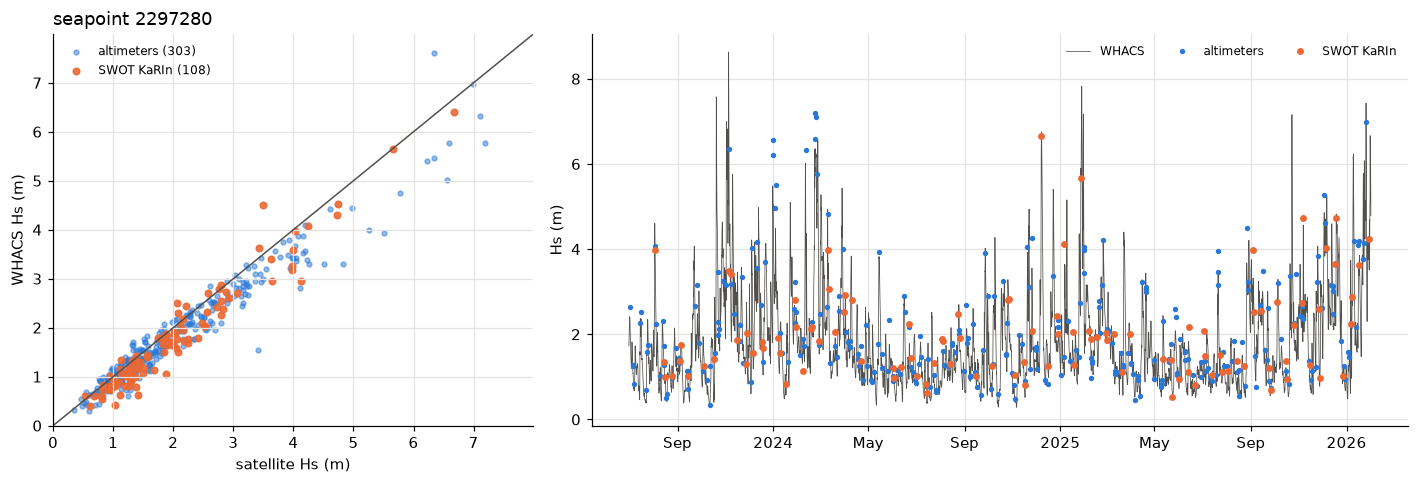

In [9]:
k = int(np.flatnonzero(nodes.seapoint.to_numpy() == best.seapoint)[0])
sw, im = pairs["swot", k], pairs["imos", k]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axes[0]
ax.scatter(im.sat_hs, im.hs, s=10, color=BLUE, alpha=0.5, label=f"altimeters ({len(im)})")
ax.scatter(sw.sat_hs, sw.hs, s=18, color=ORANGE, alpha=0.9, label=f"SWOT KaRIn ({len(sw)})")
top = float(np.nanmax([im.sat_hs.max(), im.hs.max(), sw.sat_hs.max(), sw.hs.max()])) * 1.05
ax.plot([0, top], [0, top], color=GREY, lw=1)
ax.set(xlabel="satellite Hs (m)", ylabel="WHACS Hs (m)", xlim=(0, top), ylim=(0, top))
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"seapoint {int(best.seapoint)}", loc="left")
ax = axes[1]
series = hs.isel(seapoint=k).to_series()
ax.plot(series.index, series.values, color=GREY, lw=0.5, label="WHACS")
ax.plot(im.index, im.sat_hs, "o", color=BLUE, ms=2.5, label="altimeters")
ax.plot(sw.index, sw.sat_hs, "o", color=ORANGE, ms=3.5, label="SWOT KaRIn")
ax.set_ylabel("Hs (m)")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## Notes

- The ranking measures how well each node matches the satellites near it, not how well it
  represents your site: a node 30 km offshore can score better than one 5 km from the coast
  just because open-sea waves are easier to model. Use `TARGET` and `MAX_DISTANCE_KM`.
- KaRIn Hs below ~1 m is biased high (+0.2-0.3 m against buoys): in calm areas a node may look
  too low partly because of the satellite.
- `swot_screened` counts the passes removed by the nadir screen; with `NADIR_SCREEN = False` a
  handful of artefact passes can dominate the RMSE of every node.
- The same code ranks any gridded hindcast: change `WHACS_URL` (and the node coordinates).
- Positive bias means the hindcast is higher than the satellite.
- Cite SWOT doi:10.5067/SWOT-SSH-D, IMOS and WHACS as in the store `license` attributes.